# TrialSentinel: will this clinical trial finish?

About one in six Phase 2 and Phase 3 trials registered on ClinicalTrials.gov is **terminated** before it
completes. Every stopped trial costs money, delays treatments and exposes patients to an experiment that
answers nothing. This notebook asks a practical question: **using only what is known on the day a trial is
registered, can we tell which designs are at risk?**

The data is the ClinicalTrials.gov export of every interventional Phase 2, Phase 2/3, Phase 1/2 and Phase 3
study with status *Completed*, *Terminated* or *Withdrawn*. The pipeline code lives in `src/trialsentinel/`;
this notebook narrates and visualizes it.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from trialsentinel import config as C
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
INK, TEAL, CRIMSON, AMBER, MUTED = "#13243B", "#0E7C86", "#B4233C", "#C28800", "#9FB3C2"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c9d3dc", "grid.color": "#e3e9ee",
              "axes.labelcolor": INK, "xtick.color": "#4a5d73", "ytick.color": "#4a5d73", "font.size": 10})
PAL = {0: TEAL, 1: CRIMSON, "Completed": TEAL, "Terminated": CRIMSON}
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight"); plt.show()

## 1. Ingestion and cleaning

In [2]:
raw = pd.read_csv(C.RAW_CSV, low_memory=False)
print(raw.shape)
raw["Study Status"].value_counts()

(90329, 30)


Study Status
COMPLETED     71934
TERMINATED    13490
WITHDRAWN      4905
Name: count, dtype: int64

In [3]:
quality = json.loads((C.ARTIFACTS_DIR / "data_quality_report.json").read_text())
pd.DataFrame(quality["steps"])[["step", "rows_before", "removed", "rows_after", "note"]]

,step,rows_before,removed,rows_after,note
0,exact / NCT duplicates,90329,0,90329,
1,"near-duplicates (same title, sponsor, start date)",90329,106,90223,multi-registrations of one protocol
2,missing / impossible start dates,90223,1105,89118,
3,first-posted date before the registry existed,89118,0,89118,
4,negative counts,89118,0,89118,
5,withdrawn trials (stopped before enrolling; se...,89118,4638,84480,
6,outside 2000-2021 start window (right-censoring),84480,9139,75341,


**Cleaning decisions**

* **Duplicates.** No NCT number appears twice, but 106 protocols were registered more than once (same title,
  sponsor and start date). Only the first registration is kept.
* **Structural anomalies.** Missing or impossible start dates are removed. Counts are checked for negatives.
  Extreme values are capped at IQR fences (k = 3), widened to the 1st/99th percentile for columns whose IQR
  is zero, such as country count, so they are not flattened.
* **Withdrawn trials** stopped before enrolling a single patient. That is a different failure than
  termination, so they are excluded from the target.
* **Right-censoring.** Trials that started after 2021 are mostly still running, and the ones already
  finished are a biased, fast-finishing sample. The modeling window is 2000–2021.

In [4]:
df = pd.read_parquet(C.PROCESSED_DIR / "trials_features.parquet")
print(f"{len(df):,} trials, termination rate {df[C.TARGET].mean():.1%}")
pd.Series(quality["outlier_capping"]).apply(pd.Series)

75,341 trials, termination rate 16.0%


,capped_iqr,abs_z_gt_3
n_sites,699,1090
n_countries,644,2058
registration_lag_days,1217,1636
n_secondary_outcomes,741,1332
n_primary_outcomes,666,877
n_collaborators,730,1091
n_interventions,417,1578
n_conditions,736,583


### The leakage trap: enrollment

The export has an `Enrollment` column, and it looks like the strongest predictor available. It is not
usable: for finished trials the registry replaces the planned target with the **actual** number of patients
enrolled. A terminated trial enrolled fewer patients *because* it was terminated. A model trained on it
would score brilliantly offline and be useless for a trial that has not started.

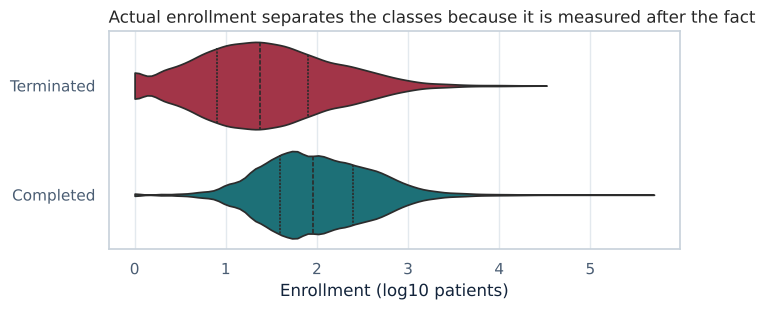

Status
Completed     90.0
Terminated    24.0
Name: Enrollment, dtype: float64

In [5]:
leak = raw[raw["Study Status"].isin(["COMPLETED", "TERMINATED"])].copy()
leak["Status"] = leak["Study Status"].str.title()
fig, ax = plt.subplots(figsize=(7, 3.2))
sns.violinplot(data=leak, x=np.log10(leak["Enrollment"].clip(lower=1)), y="Status", palette=PAL, cut=0, ax=ax, inner="quartile")
ax.set_xlabel("Enrollment (log10 patients)"); ax.set_ylabel("")
ax.set_title("Actual enrollment separates the classes because it is measured after the fact", loc="left")
save("01_enrollment_leakage")
leak.groupby("Status")["Enrollment"].median()

Excluded for the same reason: completion dates (duration), results flags, document uploads and last-update dates.

In [6]:
pd.Series(quality['excluded_for_leakage'], name='excluded')

0    Enrollment (export holds ACTUAL enrollment; te...
1    Primary Completion Date / Completion Date (dur...
2    Study Results, Results First Posted, Study Doc...
Name: excluded, dtype: str

## 2. Feature engineering

Every feature is computable at registration:

| Group | Features |
|---|---|
| Design | phase, allocation, intervention model, blinding level, primary purpose, placebo arm |
| Population | sex, age groups |
| Interventions | drug / biological / device / behavioral / procedure flags, number of interventions |
| Footprint | number of sites and countries, US site, collaborators |
| Sponsor history | trials the sponsor started before this one; termination rate of the sponsor's trials that *finished before this one started* (time-respecting, no look-ahead) |
| Registration | start year, days between start and registration, pilot/feasibility wording |
| Condition | therapeutic area (keyword taxonomy), primary condition (14k values, target-encoded) |
| Composite indicators | site dispersion index (countries per site), outcome burden score, eligibility breadth, design rigor score |

In [7]:
num = C.SKEWED_NUMERIC + C.MNAR_NUMERIC + C.ORDINAL_NUMERIC + C.ENGINEERED
miss = df[C.ALL_FEATURES].isna().mean().sort_values(ascending=False)
miss[miss > 0].to_frame("missing share")

,missing share
sponsor_prior_termination_rate,0.229410
n_countries,0.064626
n_sites,0.064626
site_dispersion_index,0.064626
intervention_model,0.018635
allocation,0.014534
masking_level,0.012583
primary_purpose,0.009371
sex,0.000491


**Missing values.** Missingness here is not random. A trial with no listed sites terminates *less* often
(9% vs 16%), because many of these are small single-centre studies that never list facilities. Sponsor
track record is missing whenever a sponsor has no finished trials yet. These columns are imputed with
**IterativeImputer (MICE)**, and a binary *missing indicator* is kept so the model can learn from the
missingness itself. Skewed count variables get **median** imputation; categoricals get an explicit
`Unknown` token.

## 3. Distributions and skewness

In [8]:
skew = df[num].skew().sort_values(ascending=False).to_frame("skewness")
skew["after log1p"] = np.log1p(df[num].clip(lower=0)).skew()
skew.round(2)

,skewness,after log1p
n_primary_outcomes,4.03,1.96
n_sites,3.41,0.91
n_countries,3.33,2.10
n_conditions,3.16,2.03
sponsor_prior_trials,2.96,0.08
sponsor_prior_termination_rate,2.84,2.06
n_collaborators,2.53,1.30
n_secondary_outcomes,2.49,0.17
registration_lag_days,2.48,0.33
outcome_burden_score,2.37,0.43


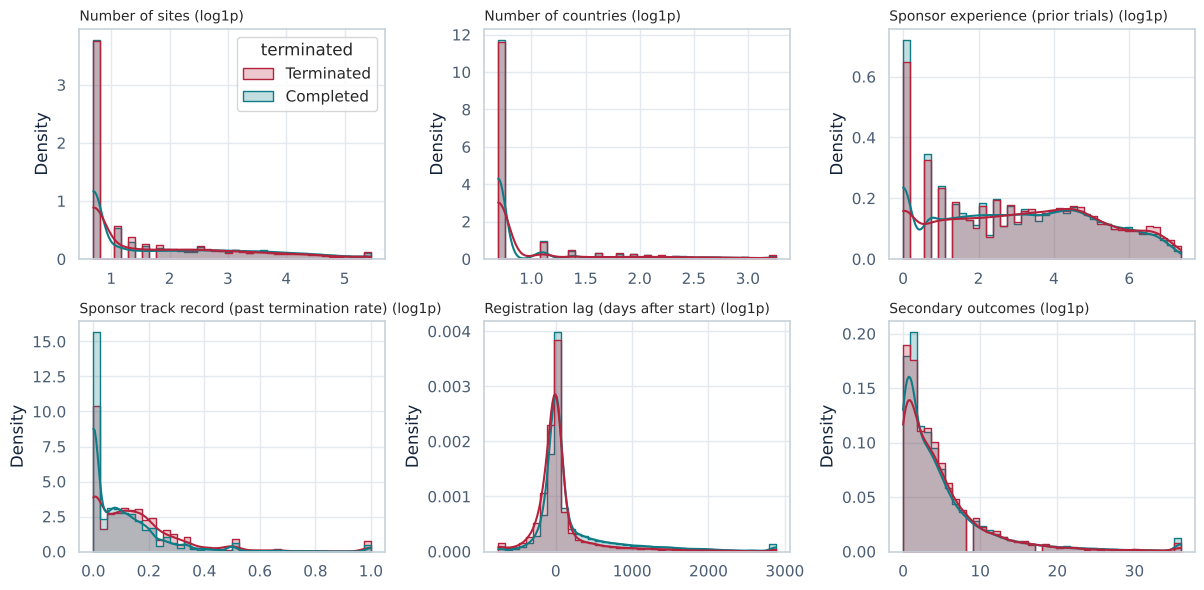

In [9]:
cols = ["n_sites", "n_countries", "sponsor_prior_trials", "sponsor_prior_termination_rate",
        "registration_lag_days", "n_secondary_outcomes"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.flat, cols):
    data = df[[c, C.TARGET]].dropna()
    x = np.log1p(data[c]) if c in ("n_sites", "n_countries", "sponsor_prior_trials") else data[c]
    sns.histplot(x=x, hue=data[C.TARGET].map({0: "Completed", 1: "Terminated"}), stat="density",
                 common_norm=False, kde=True, palette=PAL, element="step", ax=ax, bins=40, legend=ax is axes.flat[0])
    ax.set_title(C.FEATURE_LABELS[c] + (" (log1p)" if x is not data[c] else ""), loc="left", fontsize=10)
    ax.set_xlabel("")
save("02_distributions")

Counts are heavily right-skewed: most trials run at one or two sites, while a few run at hundreds.
A log transform brings skewness close to zero, which matters for the logistic regression baseline (the tree
models do not care). Sponsor track record shows the clearest separation between completed and terminated
trials.

## 4. Correlation and multicollinearity

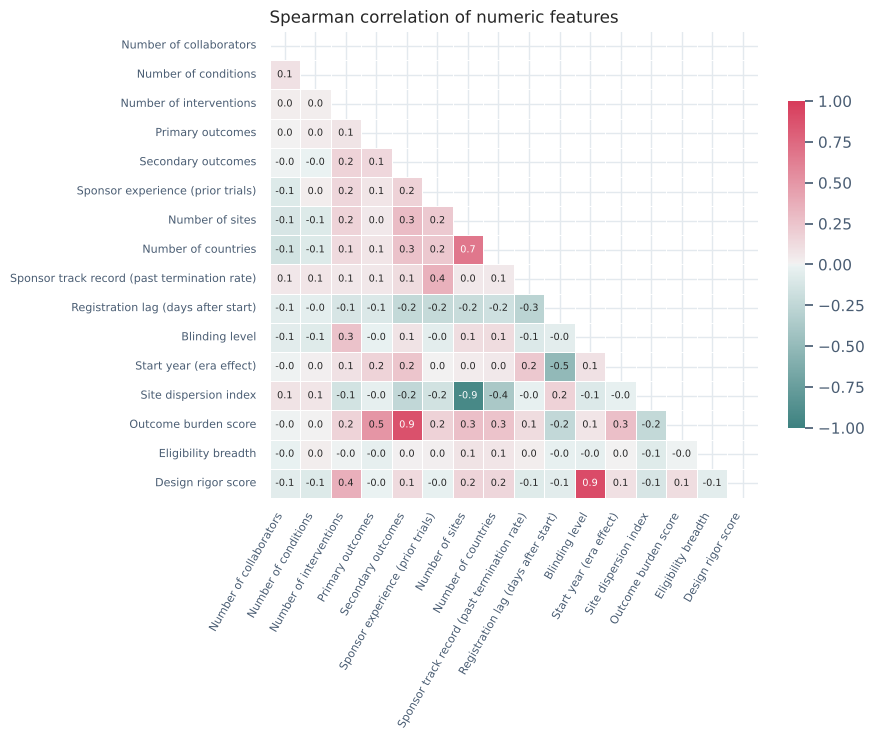

In [10]:
corr = df[num].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(190, 5, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".1f", annot_kws={"size": 7}, linewidths=.5, ax=ax, cbar_kws={"shrink": .7})
ax.set_xticklabels([C.FEATURE_LABELS[c] for c in corr.columns], rotation=60, ha="right", fontsize=8)
ax.set_yticklabels([C.FEATURE_LABELS[c] for c in corr.index], fontsize=8)
ax.set_title("Spearman correlation of numeric features", loc="left")
save("03_correlation")

In [11]:
from trialsentinel.preprocess import vif_table
meta = json.loads((C.ARTIFACTS_DIR / "model_metadata.json").read_text())
before = vif_table(df, num).round(2)
print("Removed by the VIF > 5 filter:", meta["vif_dropped"])
before.merge(pd.DataFrame(meta["vif_final"]).rename(columns={"vif": "vif after filter"}), on="feature", how="left")

/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


Removed by the VIF > 5 filter: [{'feature': 'outcome_burden_score', 'vif': 1000799917193443.5}]


/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,feature,vif,vif after filter
0,n_primary_outcomes,1.000800e+15,1.05
1,n_secondary_outcomes,1.000800e+15,1.22
2,outcome_burden_score,1.000800e+15,NaN
3,design_rigor_score,4.870000e+00,4.85
4,masking_level,4.640000e+00,4.62
5,n_sites,2.700000e+00,2.71
6,n_countries,2.300000e+00,2.30
7,site_dispersion_index,1.410000e+00,1.41
8,start_year,1.330000e+00,1.33
9,registration_lag_days,1.300000e+00,1.30


The outcome burden score is an exact linear combination of primary and secondary outcome counts, so its VIF is
infinite. The filter removes **engineered composites first** when they collide with the raw counts they
were built from, keeping the more interpretable raw features. The final numeric set has every VIF ≤ 5.

## 5. Cohort analysis: completed vs terminated

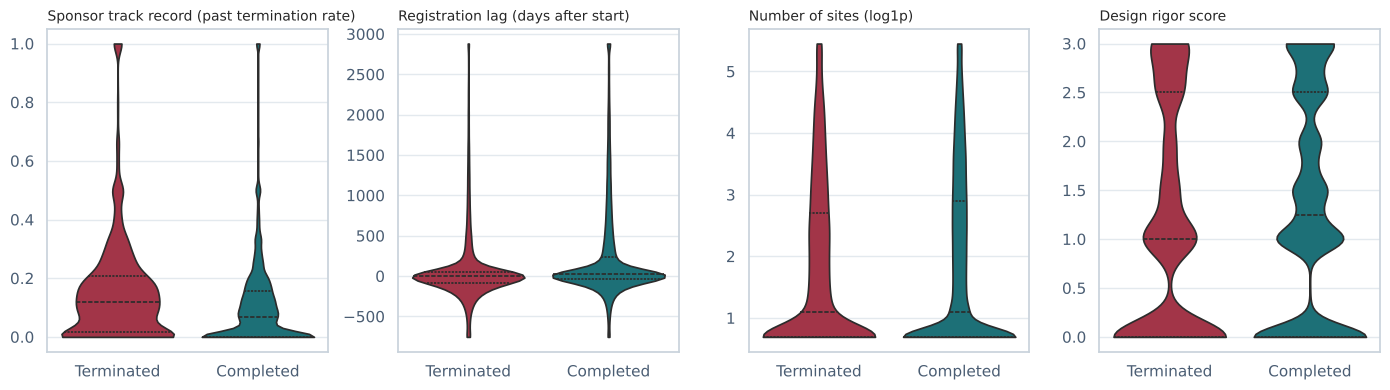

In [12]:
long = df.assign(Status=df[C.TARGET].map({0: "Completed", 1: "Terminated"}))
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axes, ["sponsor_prior_termination_rate", "registration_lag_days", "n_sites", "design_rigor_score"]):
    y = np.log1p(long[c]) if c == "n_sites" else long[c]
    sns.violinplot(data=long, x="Status", y=y, palette=PAL, cut=0, inner="quartile", ax=ax)
    ax.set_title(C.FEATURE_LABELS[c] + (" (log1p)" if c == "n_sites" else ""), loc="left", fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel("")
save("04_cohort_violins")

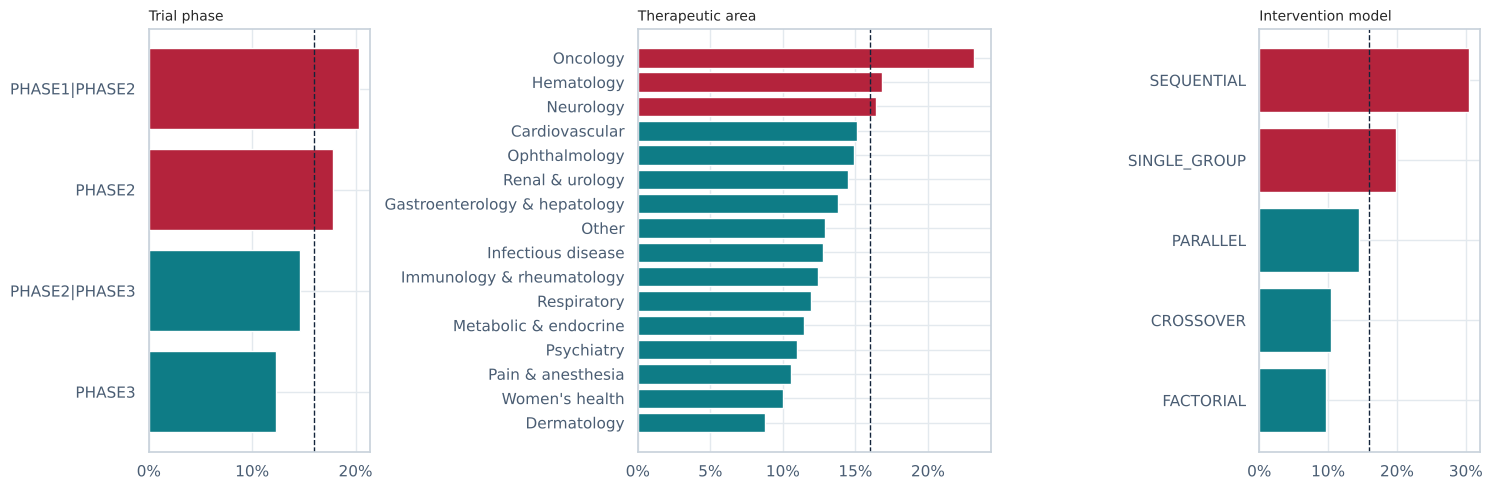

In [13]:
segs = ["phase", "therapeutic_area", "funder_type", "intervention_model", "allocation"]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6, 1]})
base = df[C.TARGET].mean()
for ax, c in zip(axes, ["phase", "therapeutic_area", "intervention_model"]):
    r = df.groupby(c)[C.TARGET].agg(["mean", "size"]).query("size >= 100").sort_values("mean")
    ax.barh(r.index.astype(str), r["mean"], color=[CRIMSON if v > base else TEAL for v in r["mean"]])
    ax.axvline(base, color=INK, ls="--", lw=1)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(C.FEATURE_LABELS[c], loc="left", fontsize=10)
save("05_segment_rates")

**What stands out**

* **Oncology** trials terminate at about 23%, far above every other area. Early-phase cancer trials often
  stop for futility or slow accrual of very specific patient populations.
* **Single-arm and sequential designs** stop more often than randomized parallel trials. Dose-escalation
  designs (sequential) are the riskiest model type.
* **Sponsor history is the clearest behavioural signal.** Sponsors whose previous trials were often stopped
  keep stopping trials: from about 11% for the best-performing sponsors to 24% for the worst.
* Trials with a **US site** terminate more often (20% vs 12%), partly reflecting the industry, oncology-heavy
  mix of US trials, and partly US reporting practice.

## 6. Feature importance baseline

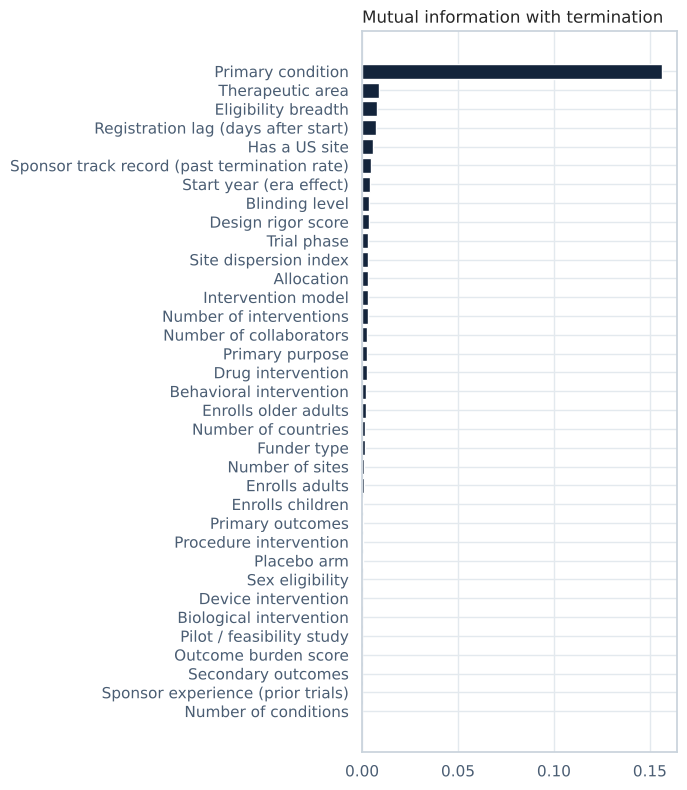

In [14]:
from sklearn.feature_selection import mutual_info_classif
X_mi = df[C.ALL_FEATURES].copy()
for c in C.LOW_CARD_CATEGORICAL + C.HIGH_CARD_CATEGORICAL:
    X_mi[c] = X_mi[c].fillna("Unknown").astype("category").cat.codes
X_mi = X_mi.fillna(X_mi.median(numeric_only=True))
disc = [c in C.LOW_CARD_CATEGORICAL + C.HIGH_CARD_CATEGORICAL + C.BINARY for c in X_mi.columns]
sample = X_mi.sample(20000, random_state=C.RANDOM_STATE)
mi = pd.Series(mutual_info_classif(sample, df.loc[sample.index, C.TARGET], discrete_features=disc,
                                   random_state=C.RANDOM_STATE), index=X_mi.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh([C.FEATURE_LABELS[c] for c in mi.index], mi.values, color=INK)
ax.set_title("Mutual information with termination", loc="left")
save("06_mutual_information")

Mutual information ranks each feature on its own. Primary condition ranks high partly because it has
thousands of values (MI is biased toward high-cardinality features), which is why it is target-encoded with
cross-fitting rather than one-hot encoded. SHAP below shows importance *inside* the trained model, where
features interact.

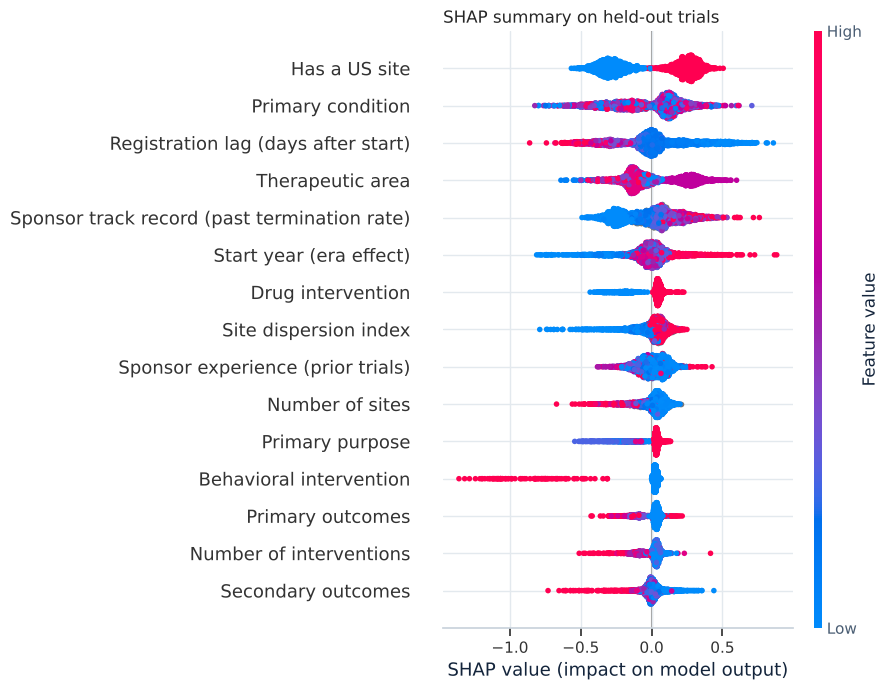

In [15]:
import shap
sv = np.load(C.ARTIFACTS_DIR / "shap_test_sample.npy")
cols = json.loads((C.ARTIFACTS_DIR / "shap_columns.json").read_text())
feat = pd.read_parquet(C.ARTIFACTS_DIR / "shap_test_features.parquet")[cols]
disp = feat.copy()
for c in disp.columns:
    if c in C.LOW_CARD_CATEGORICAL + C.HIGH_CARD_CATEGORICAL:
        disp[c] = disp[c].astype("category").cat.codes  # colour scale only; SHAP values are unaffected
shap.summary_plot(sv, disp.astype(float), feature_names=[C.FEATURE_LABELS.get(c, c) for c in cols],
                  max_display=15, show=False, plot_size=(9, 7))
plt.title("SHAP summary on held-out trials", loc="left")
save("07_shap_summary")

## 7. Model selection

In [16]:
print("Imbalance experiment (LightGBM, 5-fold CV):")
display(pd.DataFrame(meta["imbalance_experiment"]).T.round(4))
print("Chosen:", meta["imbalance_strategy"])
comp = pd.DataFrame(meta["models"]).T[["cv_pr_auc", "cv_roc_auc", "val_pr_auc", "val_roc_auc", "trials", "minutes", "sampling"]]
comp

Imbalance experiment (LightGBM, 5-fold CV):


,cv_pr_auc,cv_roc_auc
none,0.3306,0.7181
class_weight,0.3285,0.7173
smotenc,0.3260,0.7153


Chosen: none


,cv_pr_auc,cv_roc_auc,val_pr_auc,val_roc_auc,trials,minutes,sampling
logreg,0.289015,0.684705,0.285992,0.688812,12,3.6,class_weight
xgboost,0.33405,0.720658,0.336808,0.726099,25,8.3,none
lightgbm,0.335564,0.722086,0.337599,0.729202,28,14.3,none
catboost,0.335001,0.721291,0.334671,0.725646,10,8.0,none


In [17]:
pd.Series(meta["test_metrics"]).round(4).to_frame("held-out test")

,held-out test
roc_auc,0.7315
pr_auc,0.3422
f1_macro,0.6271
f1_terminated,0.3837
precision,0.3555
recall,0.4167
accuracy,0.7860
brier,0.1211
base_rate,0.1599
top_decile_precision,0.4115


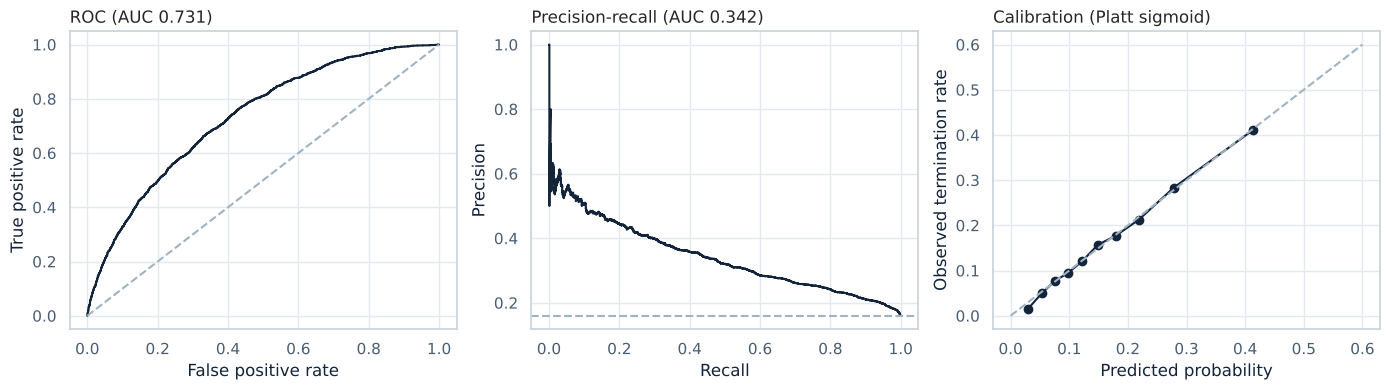

In [18]:
import joblib
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
b = joblib.load(C.ARTIFACTS_DIR / "model_bundle.joblib")
y = df[C.TARGET].values; idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=y, random_state=C.RANDOM_STATE)
va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=C.RANDOM_STATE)
p = b["calibrator"].predict_proba(b["preprocessor"].transform(df.iloc[te][b["features"]]))[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fpr, tpr, _ = roc_curve(y[te], p); axes[0].plot(fpr, tpr, color=INK); axes[0].plot([0, 1], [0, 1], ls="--", color=MUTED)
axes[0].set_title(f"ROC (AUC {meta['test_metrics']['roc_auc']:.3f})", loc="left"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
pr, rc, _ = precision_recall_curve(y[te], p); axes[1].plot(rc, pr, color=INK); axes[1].axhline(y[te].mean(), ls="--", color=MUTED)
axes[1].set_title(f"Precision-recall (AUC {meta['test_metrics']['pr_auc']:.3f})", loc="left"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
fp, mp = calibration_curve(y[te], p, n_bins=10, strategy="quantile"); axes[2].plot(mp, fp, marker="o", color=INK); axes[2].plot([0, .6], [0, .6], ls="--", color=MUTED)
axes[2].set_title("Calibration (Platt sigmoid)", loc="left"); axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed termination rate")
save("08_model_curves")

In [19]:
pd.DataFrame(meta['risk_tiers'])

,tier,range,share,observed_termination_rate,count
0,Low,"[0.0, 0.1]",0.359848,0.054586,4067
1,Moderate,"[0.1, 0.2]",0.348080,0.146670,3934
2,High,"[0.2, 0.35]",0.214210,0.256919,2421
3,Critical,"[0.35, 1.0]",0.077862,0.438636,880


In [20]:
pd.Series(meta['temporal_validation'])

train             start 2000-2014
test              start 2017-2021
n_train                     50540
n_test                      17246
roc_auc                  0.680696
pr_auc                   0.348609
test_base_rate           0.214079
dtype: object

## 8. Conclusions

* A model that only sees **registration-time design** ranks trials well above chance. Precision-recall is
  the honest metric here because terminations are the minority class (random guessing gives about 0.16).
  The riskiest tenth of trials stop at more than 2.5× the average rate, and the calibrated risk tiers match
  observed rates closely (Low about 5%, Critical about 44%).
* The patterns **mostly carry forward in time**: trained on 2000–2014 starts and tested on 2017–2021 starts,
  ROC-AUC falls from about 0.73 to 0.68. Termination rose from 14% to 21% between those periods, partly for real
  and partly from right-censoring (long recent trials are still running), so scores for recent designs carry
  more uncertainty.
* Among factors a sponsor controls, broader site networks, more fully specified outcomes and randomized
  designs go with lower risk. The single biggest flag, a US site, partly reflects which trials run in the US
  (industry-sponsored, oncology-heavy) rather than geography itself, a reminder that SHAP explains the model,
  not causation.
* **Limitations.** Many terminations are business decisions or slow recruitment that no design field can
  see. The export lacks planned enrollment and eligibility text, which would likely add signal. Use the score
  as a prompt to question a design, never as a verdict on a trial.